# 10. Why do the two exponents of Table 1 differ?

Table 1 of the paper gives two exponents per dataset.

- **γ_cal** sets the scale ratio of the fractal, λ = η^(1/(2−γ)). It comes from the
  calibration chain (`src/calibration.py`, notebooks in `calibration/`). The 2PCF is
  computed in metres with `methods_two_point_correlation`, 20 logarithmic bins from the
  mean nearest-neighbour distance up to `rmax` (200 km for Belgium, 160 km otherwise),
  and the power law is fitted on bins 1 to 18, weighted by the spread of the random
  catalogues.
- **γ̂** is measured on the 2PCF used for the model comparison (`compute_2pcf_norm` in
  `src/synthesis_utils.py`), on the extract of N = 3000 nodes. There, 18 logarithmic
  bins go from half the mean nearest-neighbour distance up to 0.55 times the largest
  pair separation, and the fit is unweighted, without the first two and the last two
  bins.

The two differ by up to 0.3. This notebook checks where the difference comes from, and
whether it changes the conclusions of the paper.

1. Both estimators on the **same** extract of nodes.
2. The two 2PCFs side by side, with their fit windows.
3. The exponent of the mixture under the γ̂ convention, over several realisations, and
   a test where λ is set from γ̂ instead of γ_cal.
4. Stability of the JSD ranks of Table 2 over 10 realisations of each model.

Running time is about 15 minutes, mostly to load the large CSV files.

In [1]:
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree

import synthesis_utils as su
import calibration as cal

N_CMP = 3000                     # size of the comparison extract (paper)
SEEDS = [42, 43, 44, 45, 46]     # realisations of the mixture (42 is the one of the paper)
N_RUNS_A = 5                     # runs of the calibration estimator on the same extract
OUT = ROOT / "out"

names = [n for n, ds in su.DATASETS.items()
         if Path(ds["path_border"]).exists() and Path(ds["path_csv"]).exists()]
print("datasets found:", names)

datasets found: ['Belgium Cities', 'RTE France', 'Gares France', 'ENEDIS France', 'France Communes', 'France Routes', 'Germany Stops', 'Swiss Stops']


## 1. Both estimators on the same nodes

For each dataset we draw the comparison extract exactly as in notebook 07 (seed 42) and
compute

- γ̂, the exponent of the paper (`compute_2pcf_norm` + `fit_powerlaw_norm`),
- γ_A, the calibration chain applied to the same extract. Its random catalogues are
  not reproducible (they are drawn inside `methods_two_point_correlation`, partly in
  parallel workers), so we run it 5 times and keep the mean and the standard deviation,
- γ̂ refitted on the calibration window only, from the mean nearest-neighbour distance
  to `rmax`.

If γ_A is close to γ_cal, the extract is not the cause of the difference. The spread of
γ_A tells how precise γ_cal itself is.

In [2]:
def fit_window(r, xi, lo, hi):
    """Unweighted power-law fit on lo <= r <= hi, positive bins only."""
    m = np.isfinite(xi) & (xi > 0) & (r >= lo) & (r <= hi)
    if m.sum() < 3:
        return np.nan
    popt, _ = curve_fit(lambda r_, g, r0: (r_ / r0) ** (-g), r[m], xi[m],
                        p0=[1.0, np.median(r[m])],
                        bounds=([0.01, 1e-12], [3, np.inf]), maxfev=10000)
    return popt[0]


rows, curves, loaded = [], {}, {}
for name in names:
    t0 = time.time()
    ds = dict(su.DATASETS[name])
    ld = su.load_dataset(ds, verbose=False)
    N = min(N_CMP, ld["N_real"])
    xy_d, r_d, xi_d = su.data_2pcf_at_N(ld, N, seed=su.SEED)
    g_hat = su.fit_powerlaw_norm(r_d, xi_d)[0]
    if N < ld["N_real"]:
        idx = np.random.default_rng(su.SEED).choice(ld["N_real"], size=N, replace=False)
        xy_m = ld["xy_metric"][idx]
    else:
        xy_m = ld["xy_metric"]
    gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(*xy_m.T), crs=ds["crs"])
    g_runs = []
    for k in range(N_RUNS_A):
        np.random.seed(k)
        r_e, l_xi = cal.data_2pcf(gdf, ld["gdf_edge"], ds["crs"], ds["rmax"])
        g_runs.append(cal.fit_gamma(r_e, l_xi)[0])
    g_A, g_A_std = float(np.mean(g_runs)), float(np.std(g_runs, ddof=1))
    nn = cKDTree(xy_m).query(xy_m, k=2)[0][:, 1].mean()
    g_win = fit_window(r_d, xi_d, nn / ld["scale_m"], ds["rmax"] / ld["scale_m"])
    xi_A = np.mean([np.asarray(x)[:len(r_e)] for x in l_xi], axis=0)
    curves[name] = dict(r_B=r_d * ld["scale_m"] / 1e3, xi_B=xi_d,
                        r_A=np.asarray(r_e) / 1e3, xi_A=xi_A)
    loaded[name] = (ds, ld, N, xy_d, r_d, xi_d, g_hat)
    rows.append(dict(dataset=name, N=N, gamma_cal=ds["gamma_data"], gamma_A_extract=g_A,
                     gamma_A_std=g_A_std, gamma_A_min=min(g_runs), gamma_A_max=max(g_runs),
                     gamma_hat=g_hat, gamma_hat_cal_window=g_win))
    print(f"{name:16s} done in {time.time() - t0:4.0f} s")

tab = pd.DataFrame(rows).set_index("dataset")
tab["extract effect (A - cal)"] = tab.gamma_A_extract - tab.gamma_cal
tab["estimator effect (hat - A)"] = tab.gamma_hat - tab.gamma_A_extract
tab["estimator effect / std(A)"] = tab["estimator effect (hat - A)"] / tab.gamma_A_std
pd.set_option("display.width", 250)
print(tab.round(3).to_string())

Belgium Cities   done in   49 s


RTE France       done in   61 s


Gares France     done in   61 s


ENEDIS France    done in   63 s


France Communes  done in   62 s


France Routes    done in   63 s


Germany Stops    done in   66 s


Swiss Stops      done in   72 s
                    N  gamma_cal  gamma_A_extract  gamma_A_std  gamma_A_min  gamma_A_max  gamma_hat  gamma_hat_cal_window  extract effect (A - cal)  estimator effect (hat - A)  estimator effect / std(A)
dataset                                                                                                                                                                                                   
Belgium Cities    815      0.808            0.811        0.029        0.784        0.859      0.515                 0.674                     0.003                      -0.296                    -10.391
RTE France       3000      0.931            0.997        0.025        0.961        1.028      1.077                 1.077                     0.066                       0.081                      3.206
Gares France     3000      0.643            0.764        0.056        0.685        0.829      0.785                 0.777                     0.121         

Two things come out of this table.

- The calibration estimator is noisy. On the same nodes, its five runs spread by 0.05
  to 0.2 (standard deviation 0.02 to 0.08), because of the random catalogues. γ_cal,
  obtained from one run on the complete dataset, carries the same uncertainty. Averaged
  over the five runs, γ_A is within 0.07 of γ_cal on seven datasets, and within 0.12
  (about two standard deviations) on the train stations. The extract is therefore not
  what separates γ_cal and γ̂.
- The gap between γ̂ and γ_A, computed on the same nodes, is about ten standard
  deviations on Belgium (−0.30, not sub-sampled at all) and on the French municipalities
  (+0.28). It is two to three standard deviations on the RTE and ENEDIS substations
  (+0.08 and +0.10), and below two on the other datasets. Restricting the γ̂ fit to the
  calibration window reduces the gap only in part, because the two estimators also
  differ in their bins and in the weighting of the fit.

## 2. The two 2PCFs and their fit windows

Open markers show the bins used by each fit.

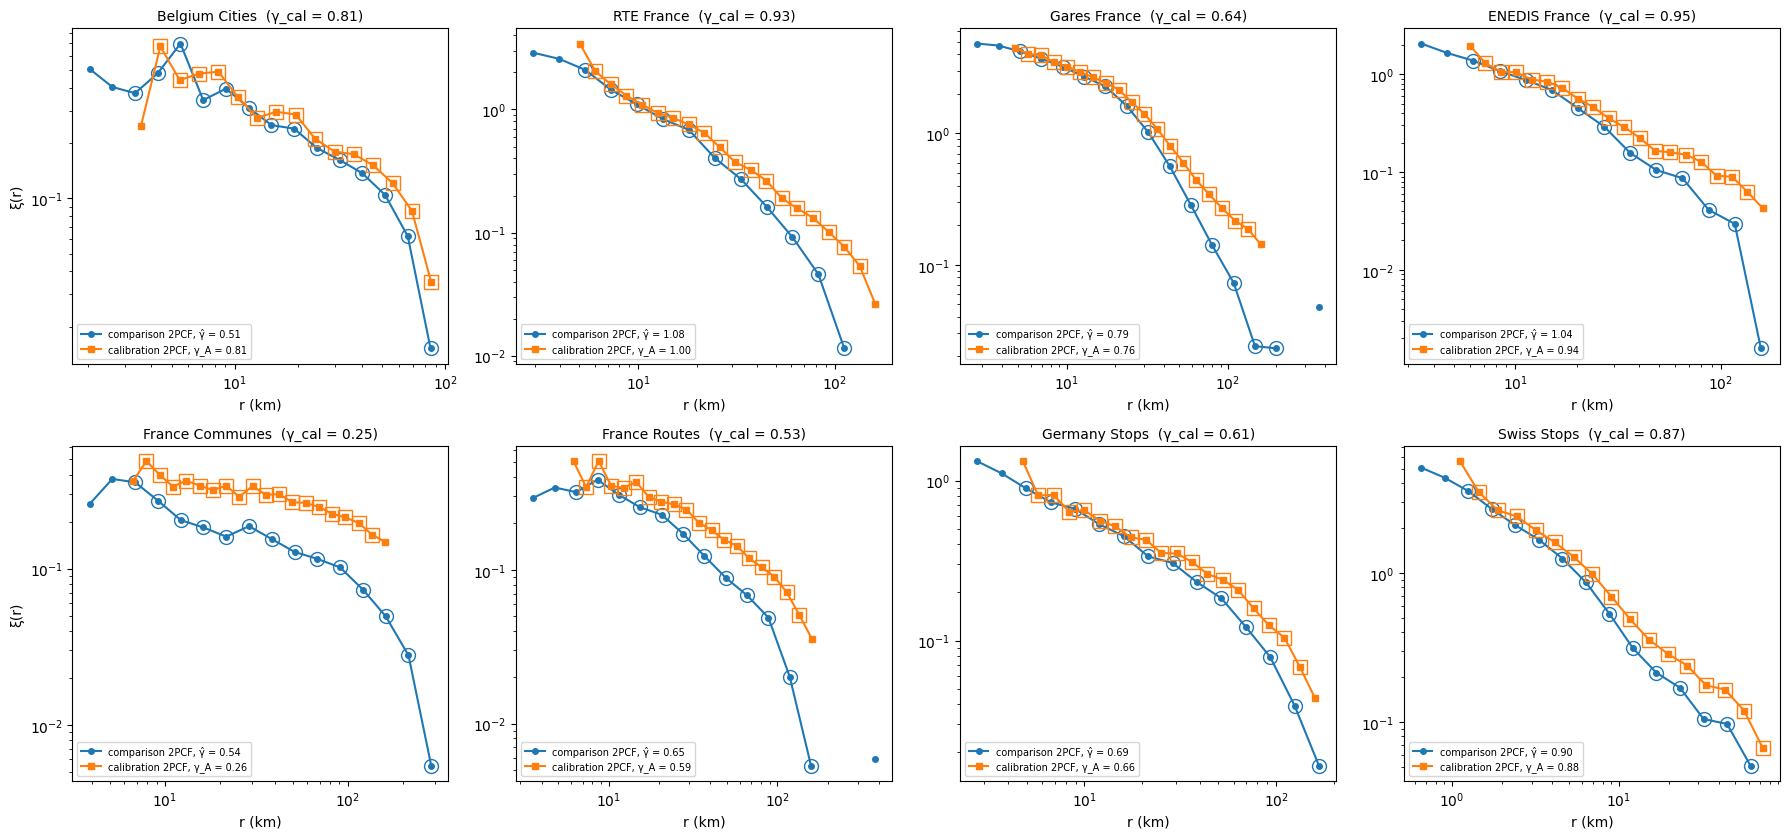

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, name in zip(axs.ravel(), names):
    c = curves[name]
    pos = lambda x: np.where(x > 0, x, np.nan)
    ax.loglog(c["r_B"], pos(c["xi_B"]), "o-", c="C0", ms=4,
              label=f"comparison 2PCF, γ̂ = {tab.loc[name, 'gamma_hat']:.2f}")
    ax.loglog(c["r_B"][2:-2], pos(c["xi_B"][2:-2]), "o", mfc="none", ms=10, c="C0")
    ax.loglog(c["r_A"], pos(c["xi_A"]), "s-", c="C1", ms=4,
              label=f"calibration 2PCF, γ_A = {tab.loc[name, 'gamma_A_extract']:.2f}")
    a, b = cal.FIT_RANGE
    ax.loglog(c["r_A"][a:b], pos(c["xi_A"][a:b]), "s", mfc="none", ms=10, c="C1")
    ax.set_title(f"{name}  (γ_cal = {tab.loc[name, 'gamma_cal']:.2f})", fontsize=10)
    ax.set_xlabel("r (km)")
    ax.legend(fontsize=7, loc="lower left")
axs[0, 0].set_ylabel("ξ(r)")
axs[1, 0].set_ylabel("ξ(r)")
fig.tight_layout()
fig.savefig(OUT / "10_two_estimators.pdf", bbox_inches="tight")
plt.show()

None of these 2PCFs is a pure power law. They bend down at large r, before the zero
crossing caused by the finite territory. A single exponent therefore depends on the
window it is fitted on.

- On the French sets the comparison window goes up to about 260 km, beyond the 160 km
  of the calibration, and it includes part of the steep drop. γ̂ is then larger than
  γ_A.
- On Belgium the comparison window stops at about 85 km and starts below the mean
  nearest-neighbour distance, where ξ is flat and noisy. γ̂ is then smaller.
- The vertical offset between the two curves comes from the position of ξ inside each
  bin (upper edge for the calibration 2PCF, geometric centre for the comparison 2PCF).
  It moves r0, not γ.

## 3. The exponent of the mixture under the same convention

The meaningful check is to compare data and mixture with the **same** estimator. For
each dataset we generate the mixture of notebook 07 with 5 seeds and measure its γ̂.
We also try a variant where λ is set from γ̂ instead of γ_cal, to see whether a
calibration consistent with the comparison estimator would do better.

In [4]:
mix_rows = []
for name in names:
    ds, ld, N, xy_d, r_d, xi_d, g_hat = loaded[name]
    for label, gam in [("gamma_cal", ds["gamma_data"]), ("gamma_hat", g_hat)]:
        dsx = dict(ds, gamma_data=float(gam))
        for s in SEEDS:
            xy = su.build_sp_mixture(dsx, ld["gdf_edge"], ld["bounds"], ld["geom_norm"],
                                     r_d, xi_d, N, seed=s)
            r_m, xi_m = su.compute_2pcf_norm(xy, ld["geom_norm"])
            mix_rows.append(dict(
                dataset=name, lambda_from=label, seed=s,
                gamma_mix=su.fit_powerlaw_norm(r_m, xi_m)[0],
                jsd_2pcf=su.js_divergence(r_d, xi_d, r_m, xi_m),
                jsd_nn=su.nn_comparison(xy_d, {"SP": xy})[1]["SP"]))
mix = pd.DataFrame(mix_rows)
agg = mix.groupby(["lambda_from", "dataset"]).agg(
    gamma_mix_mean=("gamma_mix", "mean"), gamma_mix_std=("gamma_mix", "std"),
    jsd_2pcf_mean=("jsd_2pcf", "mean"), jsd_nn_mean=("jsd_nn", "mean"))
summary = tab[["gamma_cal", "gamma_A_extract", "gamma_A_std", "gamma_hat"]].join(
    agg.loc["gamma_cal"].add_suffix(" (λ from γ_cal)")).join(
    agg.loc["gamma_hat"].add_suffix(" (λ from γ̂)"))
pd.set_option("display.width", 250)
print(summary.round(4).to_string())
print("\nmean over datasets:")
print(summary.mean().round(4).to_string())
for col in ["jsd_2pcf_mean", "jsd_nn_mean"]:
    better = (summary[f"{col} (λ from γ_cal)"] < summary[f"{col} (λ from γ̂)"]).sum()
    print(f"{col}: λ from γ_cal is better on {better} of {len(summary)} datasets")

  L=10: 452 inside < 718, trying L=11


  L=10: 438 inside < 718, trying L=11


  L=10: 656 inside < 718, trying L=11


  L=4: 726 inside < 773, trying L=5


  L=4: 723 inside < 773, trying L=5


  L=12: 1,658 inside < 2,158, trying L=13


... (7 outputs left out)

  L=4: 1,696 inside < 2,088, trying L=5


  L=4: 2,045 inside < 2,088, trying L=5


  L=4: 1,543 inside < 2,088, trying L=5


                 gamma_cal  gamma_A_extract  gamma_A_std  gamma_hat  gamma_mix_mean (λ from γ_cal)  gamma_mix_std (λ from γ_cal)  jsd_2pcf_mean (λ from γ_cal)  jsd_nn_mean (λ from γ_cal)  gamma_mix_mean (λ from γ̂)  gamma_mix_std (λ from γ̂)  jsd_2pcf_mean (λ from γ̂)  jsd_nn_mean (λ from γ̂)
dataset                                                                                                                                                                                                                                                                                              
Belgium Cities       0.808           0.8111       0.0285     0.5147                         0.9046                        0.1807                        0.0154                      0.1461                      0.7732                     0.1125                     0.0009                   0.0475
RTE France           0.931           0.9967       0.0251     1.0772                         0.9980                    

With the calibration of the paper (λ from γ_cal), the exponent of the mixture measured
like γ̂ is usually within 0.1 to 0.2 of γ̂ of the data, but it changes a lot from one
realisation to the next (standard deviation of 0.08 to 0.19), and it is far off on
Belgium. Setting λ from γ̂ does not help. The mixture then overshoots on the sets with
a large γ̂ (RTE, ENEDIS), and both JSDs are lower with λ from γ_cal on five of the
eight datasets. The mean JSD over datasets is lower with λ from γ̂, but only because of
one realisation on Belgium where the mixture is far from the data, a consequence of the
fragile amplitude ratio ρ (notebook 00, section 6bis). The calibration of the paper is
kept. What changes is the reading of Table 1. The gap between γ_cal and
γ̂ measures how much a single exponent depends on the fit window, on 2PCFs that are
only approximately power laws. It is not an error of the calibration, and it is not a
sub-sampling effect.

## 4. Are the JSD ranks stable over realisations?

Table 2 of the paper ranks the models with one realisation of each (seed 42). The cache
of `scripts/compute_all.py` also holds the mean JSD over 10 independent realisations
(`band_*`). We compare the two rankings.

In [5]:
MODELS = ["SP", "Poisson", "LGCP", "Hawkes", "Cox Hawkes"]
single, band, nn = {}, {}, {}
for name in names:
    f = su.CACHE_DIR / f"{su.cache_slug(name)}.npz"
    if not f.exists():
        continue
    d = np.load(f, allow_pickle=True)
    single[name] = {m: float(d[f"{m}_jsd"]) for m in MODELS}
    band[name] = {m: float(d[f"band_{m}_jsd_mean"]) for m in MODELS}
    nn[name] = {m: float(d[f"nn_jsd_{m}"]) for m in MODELS}
if single:
    ranks = pd.DataFrame({
        "2PCF, one realisation (Table 2)": pd.DataFrame(single).T.rank(axis=1).mean(),
        "2PCF, mean of 10 realisations": pd.DataFrame(band).T.rank(axis=1).mean(),
        "NN distances, one realisation": pd.DataFrame(nn).T.rank(axis=1).mean(),
    })
    print(f"mean JSD rank over {len(single)} datasets (1 = best):")
    print(ranks.round(2).to_string())
    first = {k: int((pd.DataFrame(v).T.rank(axis=1)["SP"] == 1).sum())
             for k, v in [("one realisation", single), ("10 realisations", band)]}
    print("\nSP ranked first on the 2PCF:", first)
else:
    print("no cache found, run scripts/compute_all.py first")

mean JSD rank over 8 datasets (1 = best):
            2PCF, one realisation (Table 2)  2PCF, mean of 10 realisations  NN distances, one realisation
SP                                     1.75                           2.25                           2.12
Poisson                                4.75                           3.88                           4.25
LGCP                                   3.00                           2.62                           2.75
Hawkes                                 2.38                           4.00                           3.88
Cox Hawkes                             3.12                           2.25                           2.00

SP ranked first on the 2PCF: {'one realisation': 5, '10 realisations': 4}


Averaged over 10 realisations, the mixture keeps the best mean rank on the 2PCF, but
its lead shrinks, and LGCP and Cox-Hawkes come close. Hawkes falls back, because some
of its realisations are far from the data. The statement of the paper should therefore
rest on the mean over realisations, and not on a single one.

In [6]:
out = summary.copy()
out.to_csv(OUT / "10_gamma_consistency.csv")
mix.to_csv(OUT / "10_mixture_realisations.csv", index=False)
print("written: out/10_gamma_consistency.csv, out/10_mixture_realisations.csv")

written: out/10_gamma_consistency.csv, out/10_mixture_realisations.csv
